# Домашнее задание

Абсолютная и относительная погрешность.

Округление и накопление ошибки

## Блок 1. Абсолютная и относительная погрешность (задачи 1–5)

### Задача 1. Ручной счёт.

Даны приближённые и точные значения. Для каждой пары вычислите абсолютную погрешность Δx и относительную δx (в %):

1. x = 3.14, x\* = π

2. x = 2.718, x\* = e

3. x = 9.8, x\* = 9.81 (ускорение свободного падения)

4. x = 0.333, x\* = 1/3



In [176]:
import math

# список ошибок     ( n   approx  exact   abs    rel) 
err_list: list[tuple[str, float, float, float, float]] = []

def add_err(n, approx, exact):
    delta = abs(approx - exact)
    sigma = delta / exact
    err_list.append((n, approx, exact, delta, sigma))
    
def print_err_table():
    print(" "*len(err_list[0][0]) + "Приближенное Точное             Δ             δ%")
    for i in err_list:
        print(f'{i[0]}{i[1]:<12.10g} {i[2]:<12.10g} {i[3]:12.10f} {i[4]*100:12.4f}')

add_err("1) ", 3.14, math.pi)
add_err("2) ", 2.718, math.e)
add_err("3) ", 9.8, 9.81)
add_err("4) ", 0.333, 1/3)

# сортируем по «качеству» приближения это 4 элемент (относительная погрешность)
err_list.sort(key = lambda x: x[4])
print_err_table()


   Приближенное Точное             Δ             δ%
2) 2.718        2.718281828  0.0002818285       0.0104
1) 3.14         3.141592654  0.0015926536       0.0507
4) 0.333        0.3333333333 0.0003333333       0.1000
3) 9.8          9.81         0.0100000000       0.1019


Совпадает ли порядок по Δx и по δx? 
> Порядок не совпадает, поскольку абсолютная погрешность показывает величину ошибки в исходных единицах, а относительная — насколько велика эта ошибка по сравнению с самим точным значением.

Таким образом, относительная погрешность позволяет объективнее сравнивать качество приближений чисел разного масштаба.


### Задача 2. Сравнение несопоставимых величин.

Инженер измерил:

* длину моста: x = 1247 м при точном 1250 м;

* диаметр болта: x = 9.7 мм при точном 10.0 мм.

Вычислите Δx и δx для обоих. 

In [177]:
err_list = []
add_err("мост ", 1247, 1250)
add_err("болт ",9.7, 10.0)
print_err_table()


     Приближенное Точное             Δ             δ%
мост 1247         1250         3.0000000000       0.2400
болт 9.7          10           0.3000000000       3.0000


Кто ошибся «сильнее»? 
> Измерение моста намного точнее, поэтому сильнее ошиблись при измерении болта.

Почему ответ зависит от того, какую погрешность мы выбрали?
> Абсолютная погрешность показывает разницу между измеренным и точным значением, а относительная — насколько велика эта ошибка по отношению к самому значению. Поэтому при сравнении измерений объектов разного масштаба относительная погрешность обычно более показательна: она позволяет оценить качество измерения независимо от размера объекта.

### Задача 3. Функция relative_error .

Напишите функцию:

def relative_error(approx, exact):

return abs(approx - exact) / abs(exact)

Добавьте защиту: если exact == 0 , вернуть float('inf') и не падать с ZeroDivisionError. 
Проверьте на четырёх парах из задачи 1.


In [178]:
def relative_error(approx, exact):
    try:
        sigma = abs(approx - exact) / abs(exact)
    except ZeroDivisionError:
        sigma = math.inf
    return sigma

print(f'{relative_error(3.14, math.pi)=}')
print(f'{relative_error(2.718, math.e)=}')
print(f'{relative_error(9.8, 9.81)=}')
print(f'{relative_error(0.333, 1/3)=}')
print(f'{relative_error(0.0001, 0)=}')



relative_error(3.14, math.pi)=0.0005069573828972128
relative_error(2.718, math.e)=0.00010367889601972718
relative_error(9.8, 9.81)=0.0010193679918450342
relative_error(0.333, 1/3)=0.0009999999999998899
relative_error(0.0001, 0)=inf


### Задача 4. Обратная задача — оценка точного значения.

Известно, что приближение x = 47.3 имеет относительную погрешность не более 0.1%. В каком диапазоне лежит x\*? 

Запишите ответ в виде интервала [a, b] с разумным числом значащих цифр.

При малых погрешностях можно считать Δx = x * δx


In [179]:
x = 47.3
rel_err = 0.1 / 100
abs_err = x * rel_err
print(f'[{x-abs_err:.3f}; {x+abs_err:.3f}]')

[47.253; 47.347]


### Задача 5. Порог по абсолютной и относительной ошибке.

Есть два датчика температуры. 

Датчик A врёт с абсолютной ошибкой не более 0.3 °C, 

датчик B — с относительной ошибкой не более 0.5%.

При какой температуре датчик B точнее (в смысле Δ ≤ 0.3)?

Решите неравенство |T| · 0.005 ≤ 0.3 и объясните, почему выбор датчика зависит от диапазона измерений.


In [180]:
sigma_b = 0.5 / 100
delta_a = 0.3
t = delta_a / sigma_b
print(f'[{-t}; {t}]')

[-60.0; 60.0]


При температуре от −60 до +60 °C датчик B имеет абсолютную погрешность не более 0,3 °C и показывает точнее датчика A. За пределами этого диапазона точнее датчик A, поскольку абсолютная погрешность датчика B становится больше 0,3 °C.

## Блок 2. Значащие цифры и округление (задачи 6–9)

### Задача 6. Подсчёт значащих цифр.

Для каждого числа определите количество значащих цифр и запишите в экспоненциальной форме так, чтобы количество значащих цифр было однозначным:

1. 0.004520
> значащие цыфры 4250 их количество 4

2. 1200
> количество значащих цифр неизвестно;

> если число записать как 1.2 * 10³ то будет 2 значащие цифры

> если число записать как 1.20 * 10³ то будет 3 значащие цифры

> если число записать как 1.200 * 10³ то будет 4 значащие цифры

3. 1.200
> 4 значащие цифры

4. 10.03
> 4 значащие цифры

5. 0.03050
> 4 значащие цифры (3050)

6. 250000
> количество значащих цифр неизвестно;

> если число записать как 2.5 * 10⁴ то будет 2 значащие цифры

> если число записать как 2.50 * 10⁴ то будет 3 значащие цифры

> если число записать как 2.500 * 10⁴ то будет 4 значащие цифры

> если число записать как 2.5000 * 10⁴ то будет 5 значащих цифр

> если число записать как 2.50000 * 10⁴ то будет 6 значащих цифр

#### Вывод:
Запись целых чисел оканчивающихся на 0 или несколько 0 (круглые числа) неоднозначна. Для их однозначного представления надо использовать экспоненциальную форму.

### Задача 7. Честная запись результата.

Измерение дало x = 4.738291 с абсолютной погрешностью Δ = 0.02. 

Запишите результат в виде x ± Δ, оставив только верные значащие цифры (правило: последняя оставляемая цифра должна быть в том же разряде, что и погрешность).
> x = 4.74 ± 0.02

Сколько значащих цифр осталось? 
> 3

Что было бы неверно в записи 4.738291 ± 0.02?
> Точность не может быть больше погрешности (может создастся иллюзия точности которой нет)


### Задача 8. Округление и banker's rounding.

Проверьте в Python:

In [181]:
print(round(0.5), round(1.5), round(2.5), round(3.5), round(-0.5), round(-1.5), round(-2.5))


0 2 2 4 0 -2 -2


Объясните, почему результат отличается от «школьного» правила «0.5 всегда вверх». 
> В Python функция round() использует правило округления к ближайшему чётному (Banker's rounding), а не школьное правило «0.5 всегда вверх».

Посчитайте, какой систематический сдвиг накопится на массиве из 106 чисел, каждое из которых — случайное k + 0.5 для k = 0..9, если округлять «вверх» вместо banker's rounding. 


In [182]:
from random import randint

cnt = 106
data = [randint(0,9) for _ in range(cnt)]

real_sum = sum(i+0.5 for i in data)
banker_round_sum = sum(round(i+0.5) for i in data)
classic_round_sum = sum(i+1 for i in data)

print('   Реальная сумма:', real_sum)
print("banker's rounding:", banker_round_sum, 'ошибка: ', banker_round_sum - real_sum)
print(' classic rounding:', classic_round_sum, 'ошибка: ', classic_round_sum - real_sum)

   Реальная сумма: 525.0
banker's rounding: 520 ошибка:  -5.0
 classic rounding: 578 ошибка:  53.0


Сделайте вывод, почему в финансах это критично.
> В финансах это критично: при обработке большого количества платежей, процентов и денежных сумм разница в правилах округления может накапливаться и приводить к существенным расхождениям в итоговых суммах.

### Задача 9. Промежуточное округление — зло.

Вычислите двумя способами S = Σ (k = 1..100) 1/k:

(а) без промежуточных округлений (float);

(б) с округлением каждого слагаемого до 3 знаков после запятой.

Сравните с эталоном math.fsum и посчитайте ΔS и δS для обоих вариантов.


In [183]:
s1 = 0.0
for k in range(1, 101):
    s1 += 1/k
    
s2 = 0.000
for k in range(1, 101):
    s2 += round(1/k, 3)
    
s3 = math.fsum(1/k for k in range(1, 101))

err_list = []
add_err("a) ", s1, s3)
add_err("б) ", s2, s3)
print_err_table()

print(f"ΔS(a) = {abs(s1 - s3):.20e}")


   Приближенное Точное             Δ             δ%
a) 5.187377518  5.187377518  0.0000000000       0.0000
б) 5.186        5.187377518  0.0013775176       0.0266
ΔS(a) = 0.00000000000000000000e+00


Во сколько раз ошибка варианта (б) больше? Сформулируйте правило.
> При округлении каждого слагаемого до трёх знаков после запятой накапливается погрешность, которая влияет на итоговую сумму. Обычное суммирование без промежуточного округления дало результат, совпадающий с эталоном math.fsum. Поэтому промежуточное округление следует избегать, а округлять результат лучше только в самом конце вычислений.

## Блок 3. Накопление ошибки и float-эксперименты (задачи 10–15)

### Задача 10. Классика 0.1 + 0.2.

Выведите 0.1 + 0.2 , сравните с 0.3 через == и через math.isclose . Найдите Δ и δ этого расхождения. 

In [184]:
def print_small_errors(approx, exact):
    delta = abs(approx - exact)
    sigma = delta / exact
    print(f"{'Приближенное':>24} {'Точное':>24} {'Δ':>16} {'δ':>24}")
    print(f'{approx:24} {exact:24} {delta:24} {sigma:24}')

s1 = 0.1 + 0.2
print(f'0.1 + 0.2 = {s1}')
print(f'0.1 + 0.2 == 0.3 is {s1 == 0.3}')
print(f'0.1 + 0.2 isclose to 0.3 is {math.isclose(s1, 0.3)}')

print_small_errors(s1, 0.3)

0.1 + 0.2 = 0.30000000000000004
0.1 + 0.2 == 0.3 is False
0.1 + 0.2 isclose to 0.3 is True
            Приближенное                   Точное                Δ                        δ
     0.30000000000000004                      0.3    5.551115123125783e-17   1.8503717077085943e-16


Объясните в 3 предложениях (без формул, «на пальцах»), почему 0.1 не представимо точно в двоичной системе.
> Дробная часть числа в двоичной системе состоит из суммы половинок, четвертинок и т.д.  1/10 так не представить, а наоборот можно т.е. любую точно записанную в 2 системе дробную часть можно точно перевести в десятичную.

### Задача 11. Катастрофическая потеря точности.

Вычислите a - b для a = 1 + 1e-15, b = 1. 
Ожидаемый ответ: 1e-15. 

Сравните с фактическим результатом в Python. 
Посчитайте относительную погрешность результата. 


In [185]:
a = 1 + 1e-15
b = 1
r = a - b
print(r)
delta = abs(r - 1e-15)
sigma = delta / 1e-15
print(f'Δ = {delta}, δ = {sigma*100:.2f}%')
print_small_errors(r, 1e-15)

1.1102230246251565e-15
Δ = 1.1022302462515646e-16, δ = 11.02%
            Приближенное                   Точное                Δ                        δ
  1.1102230246251565e-15                    1e-15   1.1022302462515646e-16      0.11022302462515646



Затем перепишите квадратичную формулу для корней ax2 + bx + c = 0 при a = 1, b = 108, c = 1 так, чтобы избежать вычитания близких чисел, и покажите, насколько точнее получается меньший корень.


In [186]:
a, b, c = 1, 108, 1
d = b*b - 4*a*c
x1 = (-b -d**0.5) / (2 * a)
x2 = (-b -d**0.5) / (2 * a)
x2_exact = c / (a * x1)
print_small_errors(r, 1e-15)

            Приближенное                   Точное                Δ                        δ
  1.1102230246251565e-15                    1e-15   1.1022302462515646e-16      0.11022302462515646


Как видно по выводу разница 11% 

### Задача 12. Накопление в цикле — сравнение стратегий.

Сложите массив из миллиона элементов [0.1] * 1_000_000 тремя способами:

1. наивный цикл for x in arr: total += x ;
2. sum(arr) ;
3. math.fsum(arr) .

Сравните с эталоном 1e5. Для каждого способа посчитайте абсолютную и относительную погрешность. 
Постройте таблицу и сделайте вывод: какой способ и во сколько раз точнее.


In [187]:
arr = [0.1] *  1_000_000
s1 = 0.0
for x in arr:
    s1 += x
s2 = sum(arr)
s3 = math.fsum(arr)
print(f'{s1=}; {s2=}; {s3=}')
print('Погрешности для наивного цикла')
print_small_errors(s1, 1e5)


s1=100000.00000133288; s2=100000.0; s3=100000.0
Погрешности для наивного цикла
            Приближенное                   Точное                Δ                        δ
      100000.00000133288                 100000.0   1.3328826753422618e-06   1.3328826753422619e-11


> Как я узнал начиная с Python 3.12: Разработчики внедрили в sum() компенсационное суммирование Ноймайера (Neumaier summation). Это оптимизированная версия алгоритма Кэхэна. Она отслеживает ошибку округления на каждом шаге и прибавляет её к следующему элементу. Для большинства повседневных распределений данных это даёт точность, неотличимую от math.fsum(), работая при этом гораздо быстрее. 

> math.fsum() — функция использует специальный алгоритм Шеwchuk (Shewchuk algorithm). Она динамически выделяет память под массив промежуточных «остатков» от округления. Из-за этого она гарантирует результат с точностью до последнего бита (ULP), независимо от того, сколько миллионов чисел вы складываете. Но этот метод требует чуть больше памяти и процессорного времени.

> В этой задаче получилось что sum и fsum сработали одинаково. Но для точных расчетов предпочтительно использовать fsum

### Задача 13. Суммирование в правильном порядке.

Возьмите массив из 106 чисел: половина — очень маленькие (1e-10), половина — большие (1e6).

Посчитайте сумму в порядке:

(а) сначала маленькие, потом большие;

(б) сначала большие, потом маленькие.

Сравните с math.fsum . Объясните, почему порядок влияет на точность и какая стратегия лучше


In [188]:
arr = [1e-10]*53 + [1e6]*53
s1 = 0.0
for x in arr:
    s1 += x
s2 = 0.0
for x in arr[::-1]:
    s2 += x
s3 = math.fsum(arr)
print(s1)
print(s2)
print(s3)


53000000.00000001
53000000.0
53000000.00000001


> Если к большому числу прибавить маленькое - маленькое может потерятся (для него не хватит битов), но если маельнике числа в начале проссумировать число может стать достаточно большим.
> В этой задаче получилось что sum и fsum сработали одинаково. Но для точных расчетов предпочтительно использовать fsum

### Задача 14. Детектор накопления погрешности.

Реализуйте «эксперимент с ростом»:

```
x = 1.0
for _ in range(10_000):
    x *= 1.0001
```

Сравните с эталоном math.exp(10000 * math.log(1.0001)). 

Посчитайте δx итерационно — на каком шаге относительная погрешность превысит 1e-9, 1e-6, 1e-3?
Постройте график δx от номера шага (matplotlib). 

Сделайте вывод: как быстро «раздувается» ошибка в мультипликативных процессах.


Значение на 10 000 шаге
            Приближенное                   Точное                Δ                        δ
      2.7181459268248984       2.7181459268249255    2.708944180085382e-14    9.966146973020348e-15


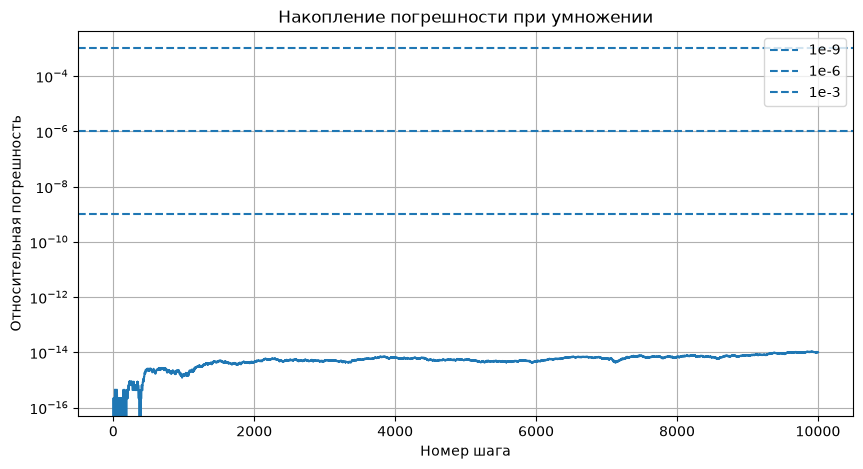

In [189]:
import matplotlib.pyplot as plt

x = 1.0
log_a = math.log(1.0001)
y = []

for step in range(1, 10_001):
    x_exact = math.exp(step * log_a)
    x *= 1.0001
    y.append(abs(x - x_exact) / x_exact)

print('Значение на 10 000 шаге')
print_small_errors(x, x_exact)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 10_001), y)
plt.axhline(1e-9, linestyle="--", label="1e-9")
plt.axhline(1e-6, linestyle="--", label="1e-6")
plt.axhline(1e-3, linestyle="--", label="1e-3")

plt.xlabel("Номер шага")
plt.ylabel("Относительная погрешность")
plt.title("Накопление погрешности при умножении")
plt.yscale("log")
plt.grid(True)
plt.legend()
plt.show()

#### Вывод:
В ходе эксперимента относительная погрешность постепенно увеличивалась, но имела небольшие колебания из-за особенностей округления чисел с плавающей точкой. За 10 000 итераций она достигла порядка 1e-14, что показывает высокую точность float в данном примере. Накопление погрешности зависит от количества операций и характера вычислений, поэтому она не обязательно растёт равномерно.

Все три порога из задания 1e-9, 1e-6, 1e-3 не достигнуты.

### Задача 15. Финансы: float vs Decimal.

Смоделируйте начисление 0.01 рубля на счёт 1_000_000 раз подряд (это 10 000 рублей):

(а) в float ;

(б) в Decimal с точностью 28 знаков.

Сравните результаты и посчитайте расхождение в рублях и в процентах. 
Дополнительно реализуйте учёт в целых копейках (int) и покажите, что он точнее float . 


In [190]:
import decimal

s1 = 0.0
for _ in range(1_000_000):
    s1 += 0.01

print('Результат в float')
print_small_errors(s1, 10000.0)

decimal.getcontext().prec = 28
s2 = decimal.Decimal()
for _ in range(1_000_000):
    s2 = s2 + decimal.Decimal('0.01')

print('Результат в decimal')
print(s2)

print('Результат в копейках')
s3 = 0
for _ in range(1_000_000):
    s3 += 1
print(s3)




Результат в float
            Приближенное                   Точное                Δ                        δ
      10000.000000171856                  10000.0   1.7185629985760897e-07     1.71856299857609e-11
Результат в decimal
10000.00
Результат в копейках
1000000


Какой результат «правильный» с точки зрения бухгалтерии? 
> Однозначно или в копейках или decimal

Почему в финансовых системах не используют float
> Многие десятичные дроби, которые мы ежедневно используем в ценниках (например, 0.1 или 0.05), невозможно точно записать в двоичной системе. Кажется, что ошибка в 15-м знаке после запятой ничтожна. Однако финансовые системы обрабатывают миллионы транзакций в день. При подсчете баланса эти микроскопические погрешности суммируются. С каждым шагом ошибка сдвигается всё ближе к реальным копейкам и рублям.

